In [ ]:
-import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 20640
Number of columns: 9


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [ ]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [ ]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
# Remove duplicate rows if any
df = df.drop_duplicates().reset_index(drop=True)

# Check missing values again
print("Total missing values:", df.isnull().sum().sum())

print("Dataset shape after preprocessing:", df.shape)

Total missing values: 0
Dataset shape after preprocessing: (20640, 9)


In [ ]:
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("MedHouseVal")

Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target:
MedHouseVal


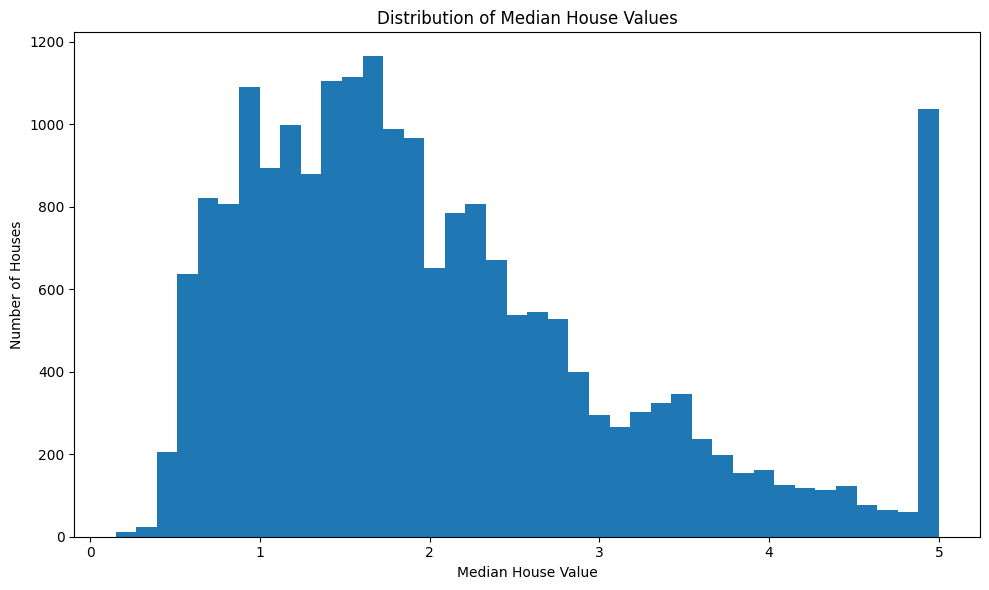

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(y, bins=40)

plt.xlabel("Median House Value")
plt.ylabel("Number of Houses")
plt.title("Distribution of Median House Values")

plt.tight_layout()
plt.show()

In [ ]:
correlation = df.corr(numeric_only=True)

target_correlation = correlation["MedHouseVal"].sort_values(ascending=False)

print(target_correlation)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


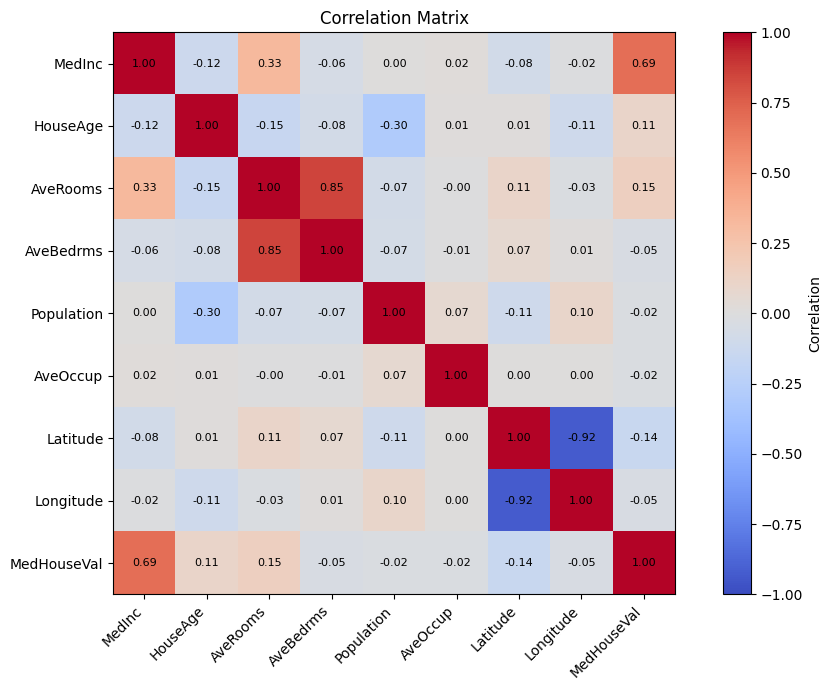

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.columns)))

ax.set_xticklabels(
    correlation.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation.columns)

for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar(im, ax=ax, label="Correlation")

ax.set_title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [ ]:
X_simple = df[["MedInc"]]
y = df["MedHouseVal"]

print(X_simple.head())

   MedInc
0  8.3252
1  8.3014
2  7.2574
3  5.6431
4  3.8462


In [ ]:
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train_simple))
print("Testing samples:", len(X_test_simple))

Training samples: 16512
Testing samples: 4128


In [ ]:
simple_model = LinearRegression()

simple_model.fit(
    X_train_simple,
    y_train_simple
)

print("Simple Linear Regression model trained successfully.")

Simple Linear Regression model trained successfully.


In [ ]:
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

Intercept: 0.4445972916907879
Coefficient: 0.4193384939381271


In [ ]:
y_pred_simple = simple_model.predict(X_test_simple)

print("First 10 predictions:")
print(y_pred_simple[:10])

First 10 predictions:
[1.14958917 1.50606882 1.90393718 2.85059383 2.00663318 2.42165249
 2.57647226 1.99229181 2.45893168 3.84677436]


In [ ]:
mae_simple = mean_absolute_error(
    y_test_simple,
    y_pred_simple
)

mse_simple = mean_squared_error(
    y_test_simple,
    y_pred_simple
)

rmse_simple = np.sqrt(mse_simple)

r2_simple = r2_score(
    y_test_simple,
    y_pred_simple
)

print("Simple Linear Regression Results")
print("--------------------------------")
print(f"MAE  : {mae_simple:.4f}")
print(f"MSE  : {mse_simple:.4f}")
print(f"RMSE : {rmse_simple:.4f}")
print(f"R²   : {r2_simple:.4f}")

Simple Linear Regression Results
--------------------------------
MAE  : 0.6299
MSE  : 0.7091
RMSE : 0.8421
R²   : 0.4589


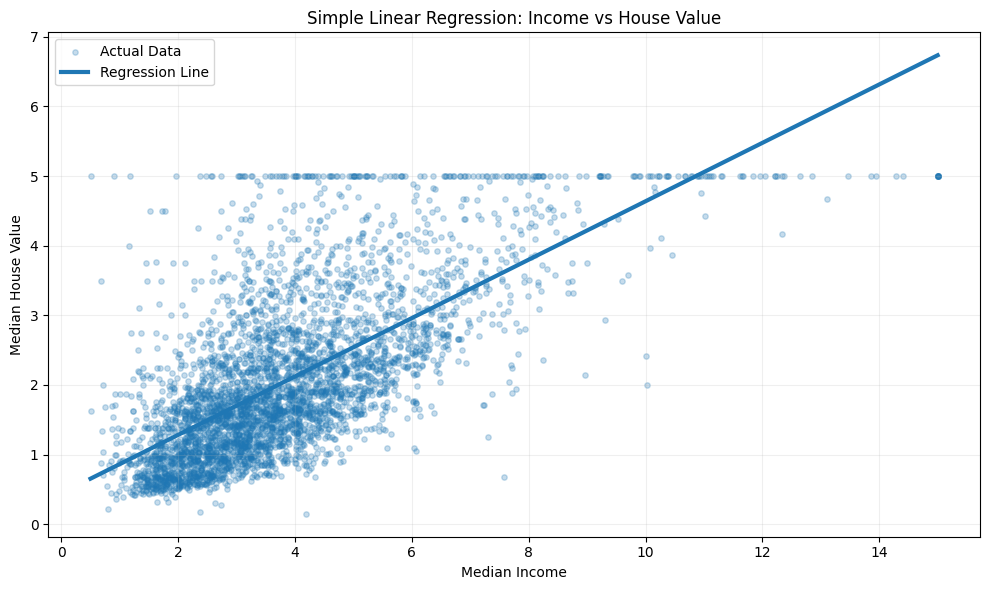

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test_simple["MedInc"],
    y_test_simple,
    alpha=0.25,
    s=15,
    label="Actual Data"
)

sorted_indices = np.argsort(X_test_simple["MedInc"].values)

X_sorted = X_test_simple.iloc[sorted_indices]

y_sorted_pred = simple_model.predict(X_sorted)

plt.plot(
    X_sorted["MedInc"],
    y_sorted_pred,
    linewidth=3,
    label="Regression Line"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Simple Linear Regression: Income vs House Value")

plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

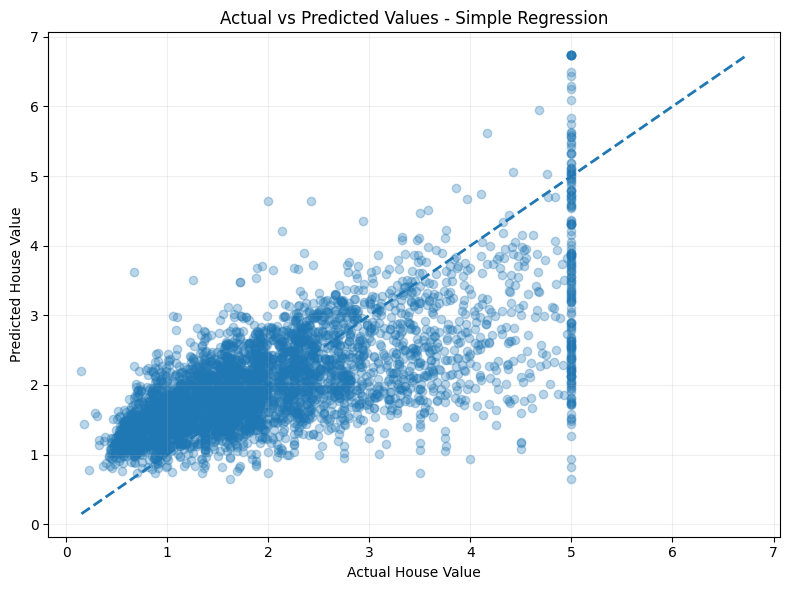

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_simple,
    y_pred_simple,
    alpha=0.3
)

min_value = min(y_test_simple.min(), y_pred_simple.min())
max_value = max(y_test_simple.max(), y_pred_simple.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted Values - Simple Regression")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
X_multiple = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Number of features:", X_multiple.shape[1])
print("Features:")
print(X_multiple.columns.tolist())

Number of features: 8
Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [ ]:
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multiple,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train_multi.shape[0])
print("Testing samples:", X_test_multi.shape[0])

Training samples: 16512
Testing samples: 4128


In [ ]:
multiple_model = LinearRegression()

multiple_model.fit(
    X_train_multi,
    y_train_multi
)

print("Multiple Linear Regression model trained successfully.")

Multiple Linear Regression model trained successfully.


In [ ]:
y_pred_multi = multiple_model.predict(X_test_multi)

print("First 10 predictions:")
print(y_pred_multi[:10])

First 10 predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [ ]:
mae_multi = mean_absolute_error(
    y_test_multi,
    y_pred_multi
)

mse_multi = mean_squared_error(
    y_test_multi,
    y_pred_multi
)

rmse_multi = np.sqrt(mse_multi)

r2_multi = r2_score(
    y_test_multi,
    y_pred_multi
)

print("Multiple Linear Regression Results")
print("----------------------------------")
print(f"MAE  : {mae_multi:.4f}")
print(f"MSE  : {mse_multi:.4f}")
print(f"RMSE : {rmse_multi:.4f}")
print(f"R²   : {r2_multi:.4f}")

Multiple Linear Regression Results
----------------------------------
MAE  : 0.5332
MSE  : 0.5559
RMSE : 0.7456
R²   : 0.5758


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "MAE": [
        mae_simple,
        mae_multi
    ],
    "MSE": [
        mse_simple,
        mse_multi
    ],
    "RMSE": [
        rmse_simple,
        rmse_multi
    ],
    "R2 Score": [
        r2_simple,
        r2_multi
    ]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,0.629909,0.709116,0.842090,0.458859
1,Multiple Linear Regression,0.533200,0.555892,0.745581,0.575788


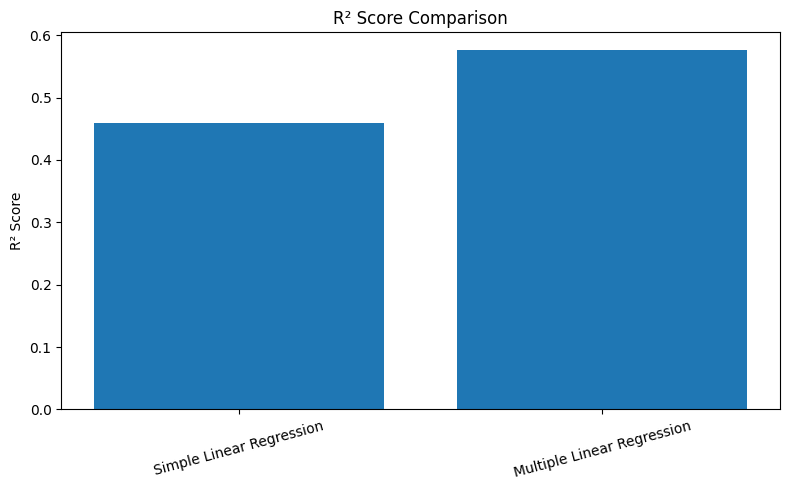

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["R2 Score"]
)

plt.ylabel("R² Score")
plt.title("R² Score Comparison")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [ ]:
coefficients = pd.DataFrame({
    "Feature": X_multiple.columns,
    "Coefficient": multiple_model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
1,HouseAge,0.009724
4,Population,-0.000002
5,AveOccup,-0.003526
2,AveRooms,-0.123323
6,Latitude,-0.419792
7,Longitude,-0.433708


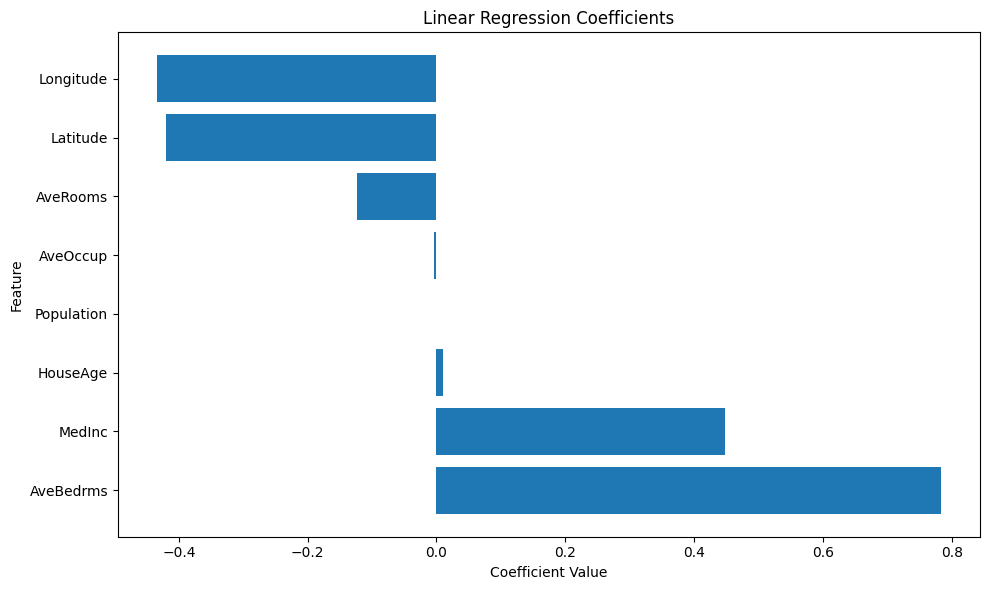

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Linear Regression Coefficients")

plt.tight_layout()
plt.show()

In [ ]:
residuals = y_test_multi - y_pred_multi

print(residuals.describe())

count    4128.000000
mean        0.003479
std         0.745664
min        -9.875331
25%        -0.460935
50%        -0.122439
75%         0.312442
max         4.148388
Name: MedHouseVal, dtype: float64


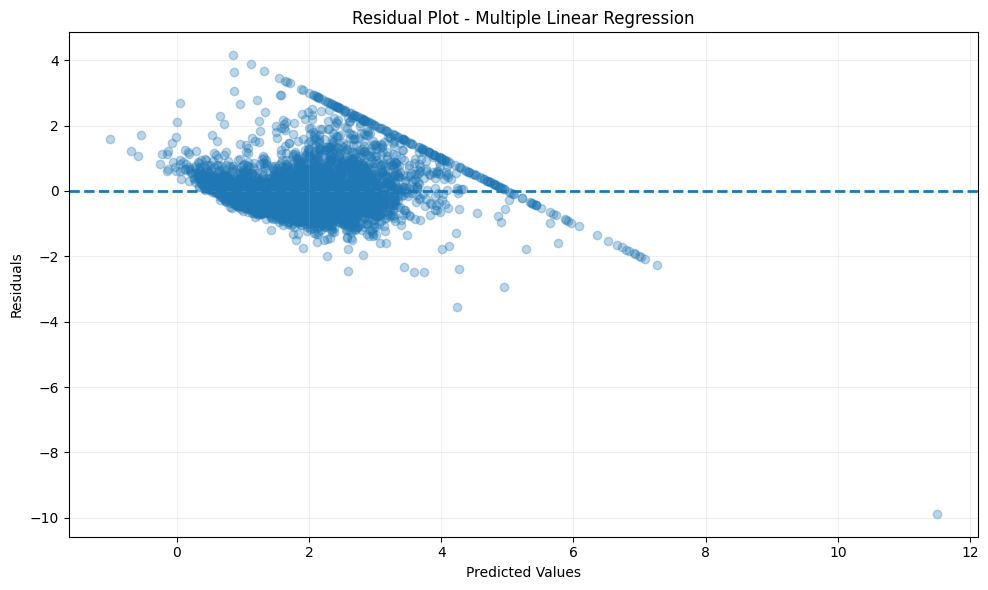

In [ ]:
residuals = y_test_multi - y_pred_multi

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_multi,
    residuals,
    alpha=0.3
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot - Multiple Linear Regression")

plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

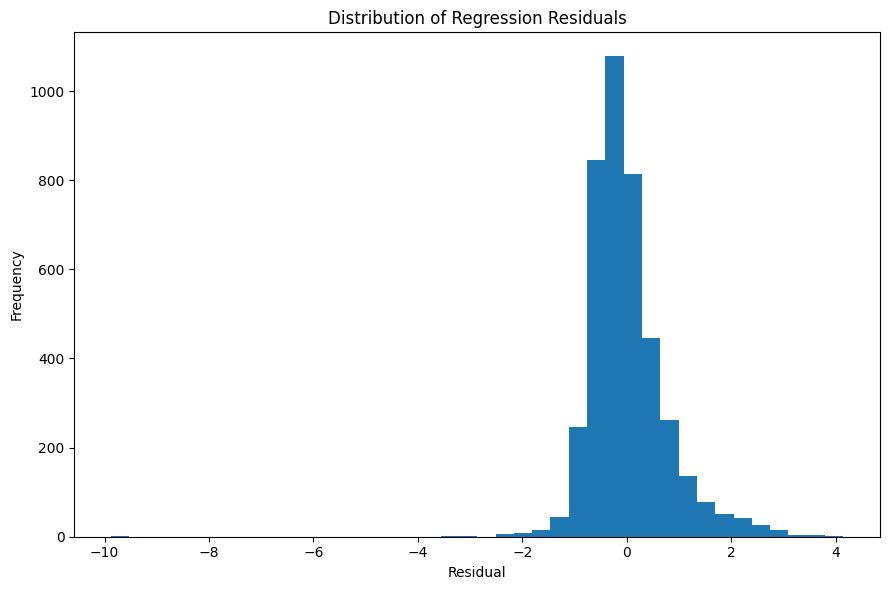

In [ ]:
plt.figure(figsize=(9, 6))

plt.hist(
    residuals,
    bins=40
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Regression Residuals")

plt.tight_layout()
plt.show()

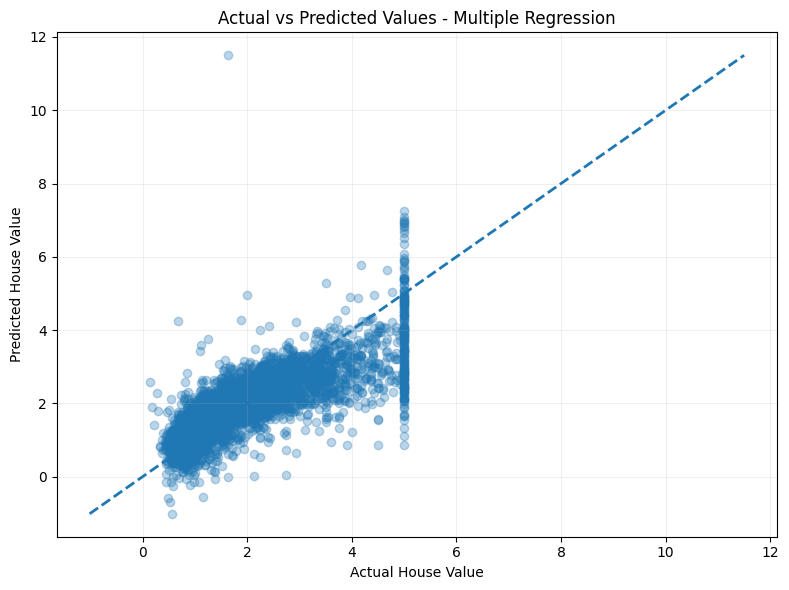

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_multi,
    y_pred_multi,
    alpha=0.3
)

min_value = min(y_test_multi.min(), y_pred_multi.min())
max_value = max(y_test_multi.max(), y_pred_multi.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted Values - Multiple Regression")

plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
print("Intercept:", multiple_model.intercept_)

for feature, coefficient in zip(
    X_multiple.columns,
    multiple_model.coef_
):
    print(f"{feature}: {coefficient:.6f}")

Intercept: -37.02327770606409
MedInc: 0.448675
HouseAge: 0.009724
AveRooms: -0.123323
AveBedrms: 0.783145
Population: -0.000002
AveOccup: -0.003526
Latitude: -0.419792
Longitude: -0.433708


In [ ]:
print("=" * 60)
print("FINAL MODEL SUMMARY")
print("=" * 60)

print("\nSimple Linear Regression")
print(f"MAE  : {mae_simple:.4f}")
print(f"MSE  : {mse_simple:.4f}")
print(f"RMSE : {rmse_simple:.4f}")
print(f"R²   : {r2_simple:.4f}")

print("\nMultiple Linear Regression")
print(f"MAE  : {mae_multi:.4f}")
print(f"MSE  : {mse_multi:.4f}")
print(f"RMSE : {rmse_multi:.4f}")
print(f"R²   : {r2_multi:.4f}")

print("\nBest model based on R²:")

if r2_multi > r2_simple:
    print("Multiple Linear Regression")
else:
    print("Simple Linear Regression")

FINAL MODEL SUMMARY

Simple Linear Regression
MAE  : 0.6299
MSE  : 0.7091
RMSE : 0.8421
R²   : 0.4589

Multiple Linear Regression
MAE  : 0.5332
MSE  : 0.5559
RMSE : 0.7456
R²   : 0.5758

Best model based on R²:
Multiple Linear Regression


In [ ]:
df.to_csv("california_housing.csv", index=False)

print("Dataset saved successfully.")

Dataset saved successfully.


In [ ]:
plt.show()

In [ ]:
plt.savefig(
    "simple_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>